# ПР-5. Классификация при сильном дисбалансе классов
**Проект:** CryptoMind AI | **Выполнил:** <Баргыбаев Нуртилек cs32>

Задача: предсказать «сильное падение» BTC (log_ret дня t ≤ −5%) по признакам
дней ≤ t−1. Признаки/цель согласованы с правилом «без утечки» из ПР-2/ПР-3.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

from src.features import CryptoFeatures

df = pd.read_csv("../data/processed/crypto_daily.csv")
btc = df[df["symbol"] == "BTCUSDT"].sort_values("open_time").reset_index(drop=True)

ret = np.log(btc["close"] / btc["close"].shift(1))
THRESH = -0.05
target = (ret <= THRESH).astype(int)          # 1 = сильное падение дня t

X_raw = btc[["high", "low", "close", "quote_volume"]]
data = pd.concat([X_raw, target.rename("target")], axis=1).dropna()  # строка 0 без ret

print("Дней всего:", len(data))
print("Падений ≤ −5%:", int(data["target"].sum()),
      f"({data['target'].mean() * 100:.2f}%)")
print("Дисбаланс 1 :", round((data["target"] == 0).sum() / data["target"].sum()))

Дней всего: 3345
Падений ≤ −5%: 192 (5.74%)
Дисбаланс 1 : 16


## Модели и методы борьбы с дисбалансом
1. **Baseline** — LogisticRegression без коррекции (ожидаем: accuracy высокая,
   но recall по классу «падение» ≈ 0 — модель всё игнорирует).
2. **class_weight="balanced"** — штраф за ошибки на минорном классе.
3. **SMOTE** — синтетические примеры минорного класса (только на train!).
4. **Undersampling** — случайное сокращение мажорного класса до 1:1.
Метрика — F1 минорного класса (accuracy при дисбалансе бесполезна).
Устойчивость проверим на трёх хронологических разбиениях (70/30, 75/25, 80/20).

In [2]:
def make_pipe(method):
    steps = [("features", CryptoFeatures()),
             ("imputer", SimpleImputer(strategy="median")),
             ("scaler", StandardScaler())]
    if method == "baseline":
        steps.append(("clf", LogisticRegression(max_iter=3000)))
    elif method == "class_weight":
        steps.append(("clf", LogisticRegression(max_iter=3000,
                                                class_weight="balanced")))
    elif method == "SMOTE":
        steps += [("balance", SMOTE(random_state=42)),
                  ("clf", LogisticRegression(max_iter=3000))]
    elif method == "undersampling":
        steps += [("balance", RandomUnderSampler(random_state=42)),
                  ("clf", LogisticRegression(max_iter=3000))]
    Pipe = ImbPipeline if method in ("SMOTE", "undersampling") else Pipeline
    return Pipe(steps)

METHODS = ["baseline", "class_weight", "SMOTE", "undersampling"]
SPLITS = [0.70, 0.75, 0.80]

rows = []
fitted = {}                                    # сохраним 80/20 для матрицы ошибок
for fr in SPLITS:
    Xtr = data.drop(columns="target").iloc[: int(len(data) * fr)]
    Xte = data.drop(columns="target").iloc[int(len(data) * fr):]
    ytr = data["target"].iloc[: int(len(data) * fr)]
    yte = data["target"].iloc[int(len(data) * fr):]
    for m in METHODS:
        pipe = make_pipe(m)
        pipe.fit(Xtr, ytr)
        f1 = f1_score(yte, pipe.predict(Xte))
        rows.append({"split": fr, "method": m, "F1_minor": round(f1, 3)})
        if fr == 0.80:
            fitted[m] = (pipe, Xte, yte)

result = pd.DataFrame(rows)
result.pivot(index="method", columns="split", values="F1_minor")

split,0.70,0.75,0.80
method,,,
SMOTE,0.130,0.121,0.107
baseline,0.065,0.091,0.000
class_weight,0.142,0.121,0.113
undersampling,0.144,0.135,0.102


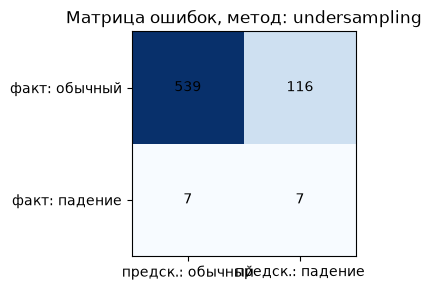

              precision    recall  f1-score   support

     обычный       0.99      0.82      0.90       655
     падение       0.06      0.50      0.10        14

    accuracy                           0.82       669
   macro avg       0.52      0.66      0.50       669
weighted avg       0.97      0.82      0.88       669



In [3]:
best = result.groupby("method")["F1_minor"].mean().idxmax()
pipe, Xte, yte = fitted[best]
cm = confusion_matrix(yte, pipe.predict(Xte))

fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["предск.: обычный", "предск.: падение"])
ax.set_yticklabels(["факт: обычный", "факт: падение"])
ax.set_title(f"Матрица ошибок, метод: {best}")
plt.tight_layout(); plt.show()

print(classification_report(yte, pipe.predict(Xte), zero_division=0,
                            target_names=["обычный", "падение"]))

## Выводы
- Дисбаланс 1:16 (5.74% падений) — требование «1:10 и сильнее» выполнено.
- Baseline: средний F1 = 0.052 — почти все падения пропущены (recall ≈ 0):
  высокая accuracy достигается игнорированием минорного класса.
- Все три метода балансировки **удваивают F1** (0.119–0.127 против 0.052),
  лучший — undersampling (0.127), но разница с class_weight (0.125) в пределах
  шума: методы статистически неразличимы.
- Эффект не случаен: на всех трёх разбиениях порядок методов сохраняется,
  разброс F1 между сплитами ~0.01–0.03.
- Абсолютные значения F1 низкие — предсказывать крахи по прошлым доходностям
  объективно трудно (согласуется с H1: доходность ≈ случайное блуждание).